In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt

import pyrite

_ = pyrite.fetch_tables()
tables_ready = True

# Importing a realistic electron beam

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/09-importing-electron-beams.py)

Inspect correlated positions, angles and energies in a GPT-format beam,
then simulate its X-ray spectrum. The input contains **96 synthetic weighted
records**, not measurements or a GPT simulation.

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve

import easygdf

beam_directory = TemporaryDirectory(prefix="pyrite-gdf-tutorial-")
beam_path = Path(beam_directory.name) / "synthetic_beam.gdf"
_ = urlretrieve(
    "https://raw.githubusercontent.com/Quantum-Light-Matter-Cooperative-QLMC/"
    "pyrite/main/docs/examples/data/synthetic_beam.gdf",
    beam_path,
)
fields = {
    item["name"]: item["value"] for item in easygdf.load(str(beam_path))["blocks"][0]["children"]
}

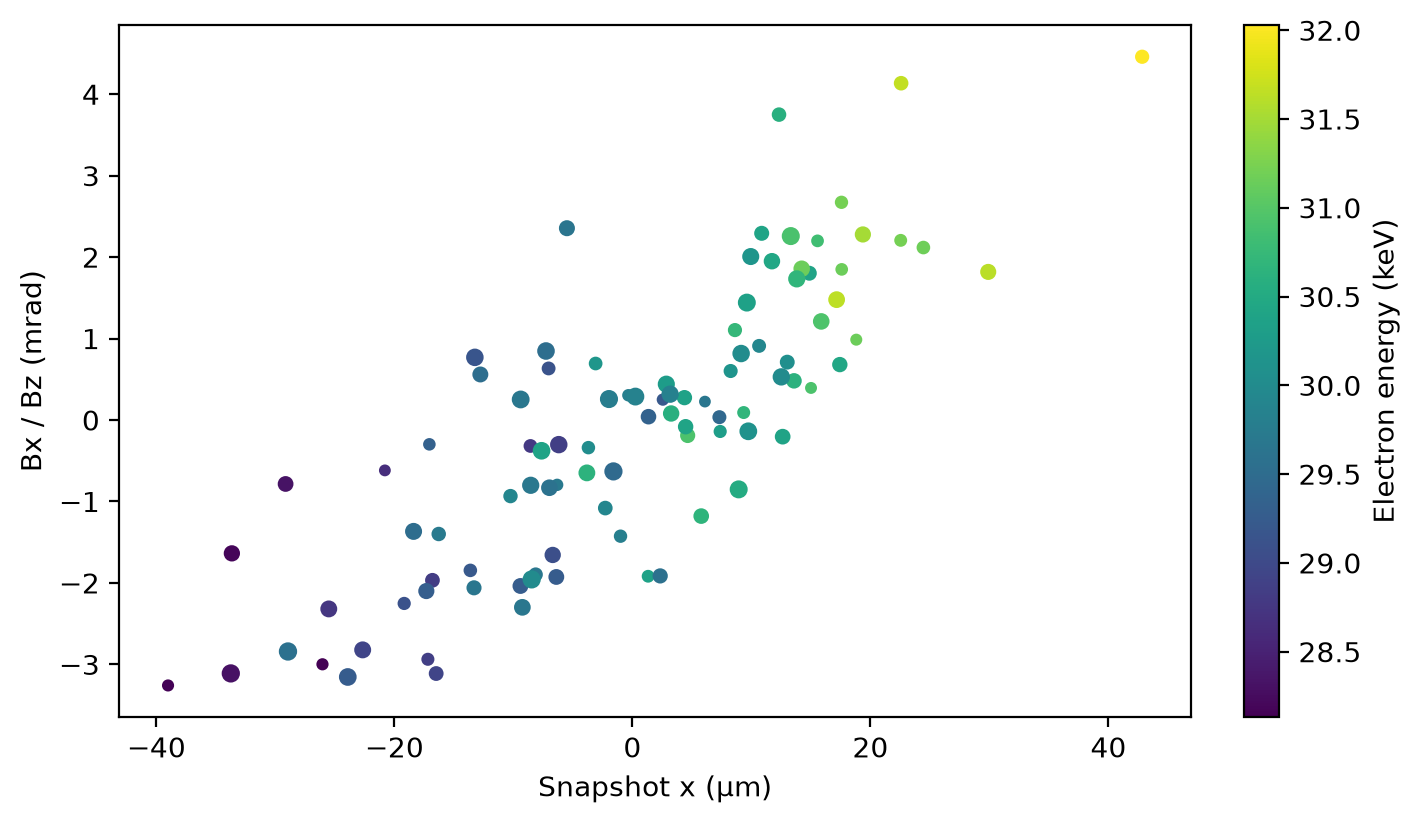

In [ ]:
_record_probability = fields["nmacro"] / fields["nmacro"].sum()
_record_energy_keV = (fields["G"] - 1) * 510.99895
fig_phase, _ax = plt.subplots(figsize=(7, 4), layout="constrained")
_points = _ax.scatter(
    fields["x"] * 1e6,
    fields["Bx"] / fields["Bz"] * 1e3,
    c=_record_energy_keV,
    s=2_000 * _record_probability,
    cmap="viridis",
)
_ax.set(xlabel="Snapshot x (µm)", ylabel="Bx / Bz (mrad)")
fig_phase.colorbar(_points, ax=_ax, label="Electron energy (keV)")
fig_phase  # noqa: B018

In [ ]:
from pyrite import simulate
from pyrite.beams import Beam
from pyrite.config import CxrReflections, FixedSampling, Numerics
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab

# Select the 1 ns snapshot and project it relative to lab z = 0.1 m.
beam = Beam.from_gdf(
    str(beam_path),
    time_s=1e-9,
    z_origin_m=0.1,
    energy_keV=30.0,
    normalization="gdf_charge",
    rep_rate_hz=1_000_000.0,
)
assert tables_ready
beam_result = simulate(
    beam,
    Slab("hopg", thickness_ang=1_000.0, tilt_deg=30.0, footprint=Footprint(1, 1)),
    Detector(observation_angle_deg=135.0),
    numerics=Numerics(
        sampling=FixedSampling(cxr_electrons=64, brem_electrons=64),
        cxr_reflections=CxrReflections(n_families=2),
        seed=1,
    ),
)

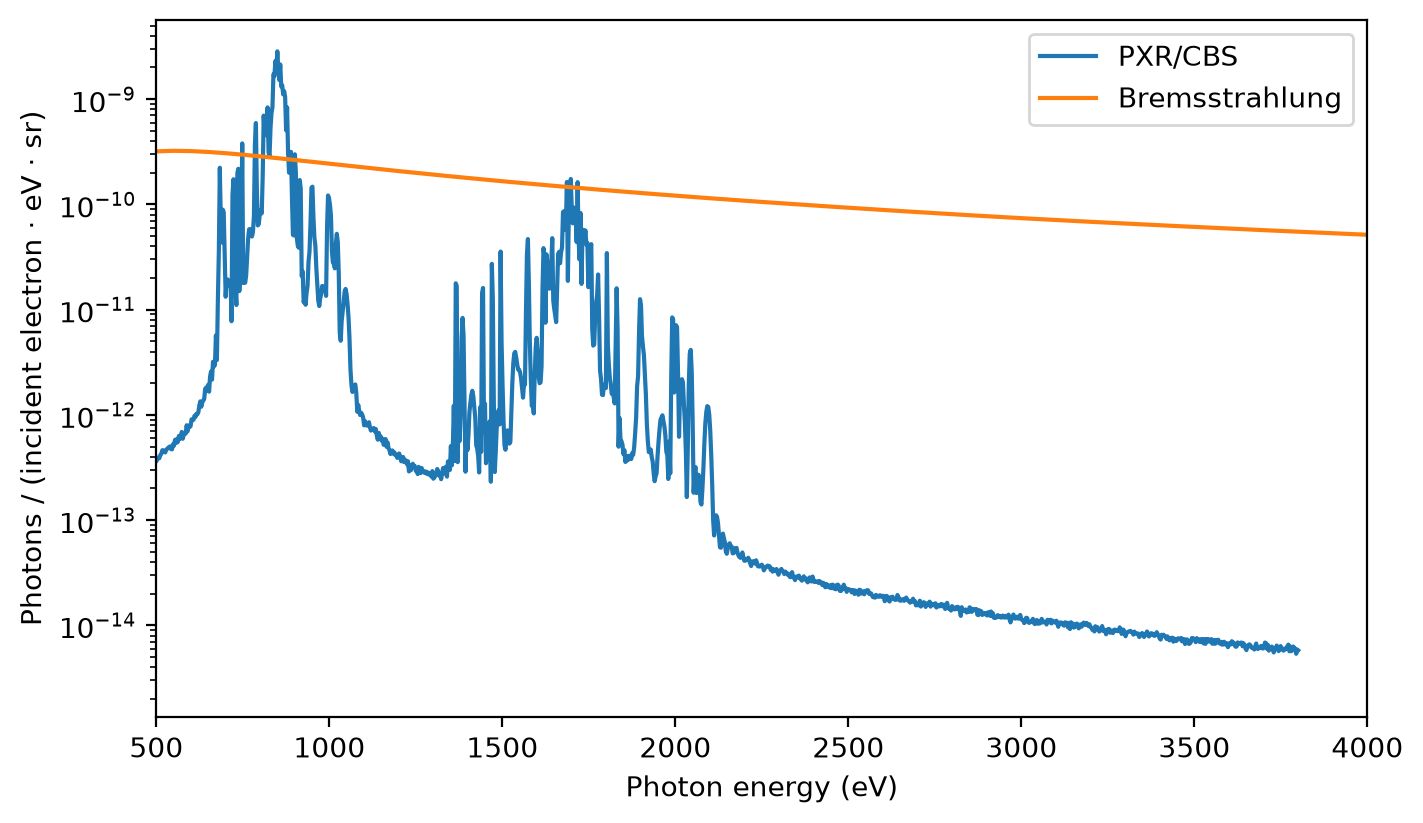

In [ ]:
fig_spectrum, _ax = plt.subplots(figsize=(7, 4), layout="constrained")
for _name, _spectrum in (
    ("PXR/CBS", beam_result.cxr.incoherent),
    ("Bremsstrahlung", beam_result.brem),
):
    _ax.plot(_spectrum.photon_energy_eV, _spectrum.density, label=_name)
_ax.set(
    xlabel="Photon energy (eV)",
    ylabel="Photons / (incident electron · eV · sr)",
    xlim=(500, 4_000),
    yscale="log",
)
_ax.legend()
fig_spectrum  # noqa: B018

Marker area shows each record's sampling probability. Importing complete
records retains the position–angle–energy correlations; `Bx`, `By` and
`Bz` are velocities divided by the speed of light.

The file represents **1 pC per bunch**: at **1 MHz**, the mean current is
**1 µA**. The 64 sampled histories per population estimate a source spectrum;
they do not set the bunch charge. The scalar `energy_keV` is a scene
placeholder; the imported records supply the individual energies.

Try replacing the synthetic input with a single forward-going snapshot
of your beam, selecting its time and coordinate origin explicitly.

## Continue learning

Next: [Transition and coherent transition radiation](10-transition-radiation.ipynb).
See the [GDF beam reference](../../reference/gdf-beams.md) for snapshot selection, coordinates and restrictions,
and the [beam API](../../reference/python-api/beams.md) for input contracts.
The reusable [synthetic fixture and license](../../examples/data/synthetic_beam.md) describe the input.
[Phase-space injection evidence](../../validation/beam-transport/beam-phase-space-injection.md) covers the sampling contract.

{download}`Download canonical Marimo notebook <../09-importing-electron-beams.py>`